In [2]:
#explain notebook functionality
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
import random
import requests
import zipfile
from tqdm.notebook import trange,tqdm
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader
from torch.distributions import Categorical

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from transformers import AutoTokenizer
os.environ["TOKENIZERS_PARALLELISM"]="false"
torch.backends.cuda.matmul.allow_tf32=True
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
class SampleCaption(nn.Module):
    def __call__(self,sample):
        return sample[random.randint(0,len(sample)-1)]
        

In [45]:
image_size = 128
batch_size = 128

In [46]:
train_transform=transforms.Compose(
    [transforms.Resize(image_size),
     transforms.RandomCrop(image_size),
     transforms.ToTensor(),
     transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225]),
     transforms.RandomErasing(p=0.5),
    ])
transform=transforms.Compose(
    [
        transforms.Resize(image_size),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225]),
    ])


In [47]:
def download_url(url,save_path,chunk_size=1024):
    if os.path.exists(save_path):
        print(f"{save_path} already exists;skipping download")
    print(f"Downloading from {url} to {save_path}...")
    response=requests.get(url,stream=True)
    total_size=int(response.headers.get("content-length",0))
    with open(save_path,"wb") as f:
        for data in response.iter_content(chunk_size=chunk_size):
            f.write(data)
    print("download complete")
def extract_zip(zip_path,extract_to):
    with zipfile.ZipFile(zip_path,"r") as zip_ref:
        folder_name=zip_ref.namelist()[0].split(os.sep)[0]
    target_path=os.path.join(extract_to,folder_name)
    if os.path.exists(target_path):
        print(f"{target_path} already exists;skipping extraction")
        return 
    print(f"Extracting {zip_path} to {extract_to}...")
    with zipfile.ZipFile(zip_path,"r") as zip_ref:
        zip_ref.extractall(extract_to)
    print("extraction completed")
def get_train_dataset_paths(base_dir="./coco_dataset"):
    os.makedirs(base_dir,exist_ok=True)
    train_images_url="http://images.cocodataset.org/zips/train2014.zip"
    ann_url="http://images.cocodataset.org/annotations/annotations_trainval2014.zip"
    train_zip_path=os.path.join(base_dir,"train2014.zip")
    ann_zip_path = os.path.join(base_dir, "annotations_trainval2014.zip")
    download_url(train_images_url, train_zip_path)
    download_url(ann_url, ann_zip_path)

    extract_zip(train_zip_path, base_dir)
    extract_zip(ann_zip_path, base_dir)

    train_images_folder = os.path.join(base_dir, "train2014")
    train_ann_file = os.path.join(base_dir, "annotations", "captions_train2014.json")

    # Verify that the required files exist
    if not os.path.isdir(train_images_folder):
        raise FileNotFoundError(
            f"Training images folder not found: {train_images_folder}"
        )
    if not os.path.exists(train_ann_file):
        raise FileNotFoundError(f"Training annotation file not found: {train_ann_file}")

    return train_images_folder, train_ann_file


def get_val_dataset_paths(base_dir="./coco_dataset"):
    os.makedirs(base_dir, exist_ok=True)

    val_images_url = "http://images.cocodataset.org/zips/val2014.zip"
    ann_url = "http://images.cocodataset.org/annotations/annotations_trainval2014.zip"

    val_zip_path = os.path.join(base_dir, "val2014.zip")
    ann_zip_path = os.path.join(base_dir, "annotations_trainval2014.zip")

    download_url(val_images_url, val_zip_path)
    download_url(ann_url, ann_zip_path)

    extract_zip(val_zip_path, base_dir)
    extract_zip(ann_zip_path, base_dir)

    val_images_folder = os.path.join(base_dir, "val2014")
    val_ann_file = os.path.join(base_dir, "annotations", "captions_val2014.json")

    # Verify that the required files exist
    if not os.path.isdir(val_images_folder):
        raise FileNotFoundError(
            f"Validation images folder not found: {val_images_folder}"
        )
    if not os.path.exists(val_ann_file):
        raise FileNotFoundError(f"Validation annotation file not found: {val_ann_file}")

    return val_images_folder, val_ann_file
    

In [8]:
train_images_folder, train_ann_file = get_train_dataset_paths()
print("Train Images Folder:", train_images_folder)
print("Train Annotation File:", train_ann_file)

val_images_folder, val_ann_file = get_val_dataset_paths()
print("Validation Images Folder:", val_images_folder)
print("Validation Annotation File:", val_ann_file)

./coco_dataset/train2014.zip already exists;skipping download
download complete
./coco_dataset/annotations_trainval2014.zip already exists;skipping download
download complete
./coco_dataset/train2014 already exists;skipping extraction
./coco_dataset/annotations already exists;skipping extraction
Train Images Folder: ./coco_dataset/train2014
Train Annotation File: ./coco_dataset/annotations/captions_train2014.json
./coco_dataset/val2014.zip already exists;skipping download
download complete
./coco_dataset/annotations_trainval2014.zip already exists;skipping download
download complete
./coco_dataset/val2014 already exists;skipping extraction
./coco_dataset/annotations already exists;skipping extraction
Validation Images Folder: ./coco_dataset/val2014
Validation Annotation File: ./coco_dataset/annotations/captions_val2014.json


In [48]:
#Datasets
train_dataset=datasets.CocoCaptions(
    root=train_images_folder,
    annFile=train_ann_file,
    transform=train_transform,
    target_transform=SampleCaption(),
)
val_dataset=datasets.CocoCaptions(
    root=val_images_folder,
    annFile=val_ann_file,
    transform=transform,
    target_transform=SampleCaption(),
)

loading annotations into memory...


Done (t=0.23s)
creating index...
index created!
loading annotations into memory...
Done (t=0.12s)
creating index...
index created!


In [49]:
num_workers = 0

train_dataloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

In [50]:
first_iter=next(iter(val_dataloader))
test_images,test_captions=first_iter
test_images.shape


torch.Size([128, 3, 128, 128])

a shoe rack with some shoes and a dog sleeping on them


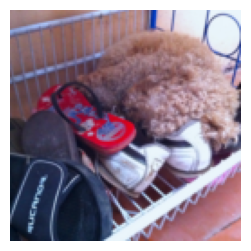

In [51]:
plt.figure(figsize=(3,3))
out=torchvision.utils.make_grid(test_images[0:1],1,normalize=True)
plt.axis(False)
plt.imshow(
    out.numpy().transpose((1,2,0))
)
caption=test_captions[0]
print(caption)

In [52]:
tokenizer=AutoTokenizer.from_pretrained("distilbert-base-uncased")


In [53]:
tokenizer.vocab_size

30522

In [54]:
print("[PAD] token id:",tokenizer.pad_token_id)
print("[CLS] token id: ",tokenizer.cls_token_id)
print("[SEP] token id: ", tokenizer.sep_token_id)


[PAD] token id: 0
[CLS] token id:  101
[SEP] token id:  102


In [55]:
tokens=tokenizer(test_captions,padding=True,truncation=True,return_tensors="pt")


In [56]:
tokens["input_ids"].shape

torch.Size([128, 23])

In [57]:
tokens["input_ids"][0].shape

torch.Size([23])

In [58]:
tokens["input_ids"]

tensor([[  101,  1037, 10818,  ...,     0,     0,     0],
        [  101,  9055,  9083,  ...,     0,     0,     0],
        [  101,  1996,  2317,  ...,     0,     0,     0],
        ...,
        [  101,  1037, 11190,  ...,     0,     0,     0],
        [  101,  1037,  2547,  ...,     0,     0,     0],
        [  101,  1037,  2611,  ...,     0,     0,     0]])

In [59]:
token_ids=tokens["input_ids"][0]
tokens["input_ids"]

tensor([[  101,  1037, 10818,  ...,     0,     0,     0],
        [  101,  9055,  9083,  ...,     0,     0,     0],
        [  101,  1996,  2317,  ...,     0,     0,     0],
        ...,
        [  101,  1037, 11190,  ...,     0,     0,     0],
        [  101,  1037,  2547,  ...,     0,     0,     0],
        [  101,  1037,  2611,  ...,     0,     0,     0]])

In [60]:
print(tokenizer.decode(token_ids))

[CLS] a shoe rack with some shoes and a dog sleeping on them [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [61]:
class TokenDrop(nn.Module):
    def __init__(self,prob=0.1,blank_token=1,eos_token=102):
        self.prob=prob
        self.eos_token=eos_token
        self.blank_token=blank_token
    def __call__(self,sample):
        mask=torch.bernoulli(self.prob*torch.ones_like(sample)).long()
        can_drop=(
        ~(sample==self.eos_token)).long()
        mask=mask*can_drop
        mask[:,0]=torch.zeros_like(mask[:,0]).long()
        replace_with=(self.blank_token*torch.ones_like(sample)).long()
        sample_out=(1-mask)*sample +mask*replace_with
        return sample_out

In [62]:
class PatchEmbedding(nn.Module):
    def __init__(self,in_channels:int=3,patch_size:int=16,d_model:int=128):
        super().__init__()
        self.patch_size=patch_size
        self.d_model=d_model
        self.unfold=nn.Unfold(kernel_size=patch_size,stride=patch_size)
        self.proj=nn.Linear(in_channels*patch_size*patch_size,d_model)
    def forward(self,x):
        batch_size,c,h,w=x.shape
        patches=self.unfold(x)
        patches=patches.transpose(1,2)
        return self.proj(patches)
        
        

In [63]:
class PositionalEncoding(nn.Module):
    def __init__(self,d_model:int):
        super().__init__()
        self.d_model=d_model
    def forward(self,x):
        device=x.device
        half_dim=self.d_model//2
        emb=math.log(10000.0)/(half_dim-1)
        emb=torch.exp(torch.arange(half_dim,device=device)*-emb)
        emb=x[:,None]*emb[None,:]
        emb=torch.cat((emb.sin(),emb.cos()),dim=-1)
        return emb

In [64]:
class MultiHeadAttention(nn.Module):
    def __init__(self,d_model:int=512,n_heads:int=8,dropout:float=0.1):
        super().__init__()
        assert(
            d_model%n_heads==0)
        self.d_model=d_model
        self.n_heads=n_heads
        self.d_key=d_model//n_heads
        self.Wq=nn.Linear(d_model,d_model)
        self.Wk=nn.Linear(d_model,d_model)
        self.Wv=nn.Linear(d_model,d_model)
        self.Wo=nn.Linear(d_model,d_model)
        self.dropout=nn.Dropout(p=dropout)
    def forward(self,query,key,value,mask=None):
        batch_size=key.size(0)
        Q=self.Wq(query)
        K=self.Wk(key)
        V=self.Wv(value)
        Q=Q.view(batch_size,-1,self.n_heads,self.d_key).permute(0,2,1,3)
        K=K.view(batch_size,-1,self.n_heads,self.d_key).permute(0,2,1,3)
        V=V.view(batch_size,-1,self.n_heads,self.d_key).permute(0,2,1,3)
        scaled_dot_product=torch.matmul(Q,K.permute(0,1,3,2))/math.sqrt(self.d_key)
        if mask is not None:
            scaled_dot_product=scaled_dot_product.masked_fill(mask==0,-float("inf"))
        attention_probs=torch.softmax(scaled_dot_product,dim=-1)
        A=torch.matmul(self.dropout(attention_probs),V)
        A=(
            A.permute(0,2,1,3)
            .contiguous()
            .view(batch_size,-1,self.n_heads*self.d_key))
        output=self.Wo(A)
        return (
            output,attention_probs,
        )
        
        
        

In [65]:
class PositionwiseFeedForward(nn.Module):
    def __init__(self,d_model:int,dropout:float=0.1):
        super().__init__()
        self.ffn=nn.Sequential(
            nn.Linear(in_features=d_model,out_features=(d_model*4)),
            nn.GELU(),
            nn.Linear(in_features=(d_model*4),out_features=d_model),
            nn.Dropout(p=dropout),
        )
    def forward(self,x):
        return self.ffn(x)
        

In [66]:
class EncoderLayer(nn.Module):
    def __init__(self,d_model:int,n_heads:int,dropout:float=0.1):
        super().__init__()
        self.attention=MultiHeadAttention(
            d_model=d_model,n_heads=n_heads,dropout=dropout)
        self.attention_layer_norm=nn.LayerNorm(d_model)
        self.position_wise_ffn=PositionwiseFeedForward(
            d_model=d_model,dropout=dropout)
        self.ffn_layer_norm=nn.LayerNorm(d_model)
        self.dropout=nn.Dropout(p=dropout)

    def forward(self,src):
        _src,attention_probs=self.attention(src,src,src,None)
        src=self.attention_layer_norm(
            src+self.dropout(_src))
        _src=self.position_wise_ffn(src)
        src=self.ffn_layer_norm(src+self.dropout(_src))
        return src,attention_probs
    
        

In [67]:
class Encoder(nn.Module):
    def __init__(
        self,
        image_size:int,
        in_channels:int,
        patch_size:int=16,
        d_model:int=128,
        n_layers:int=3,
        n_heads:int=4,
        dropout:float=0.1,
    ):
        super().__init__()
        self.patch_size=patch_size
        self.patch_emb=PatchEmbedding(patch_size=patch_size,in_channels=in_channels,d_model=d_model)
        seq_length=(image_size//patch_size)**2
        self.pos_embedding=nn.Parameter(
            torch.empty(1,seq_length,d_model).normal_(std=0.02))
        self.layers=nn.ModuleList(
            [
                EncoderLayer(d_model=d_model,n_heads=n_heads,dropout=dropout)
                for layer in range(n_layers)])
        self.dropout=nn.Dropout(p=dropout)
    def forward(self,src):
        batch_size=src.shape[0]
        src=self.patch_emb(src)
        src=src+self.pos_embedding
        for layer in self.layers:
            src,attention_probs=layer(src)
        self.attention_probs=attention_probs
        return src
        
    

In [68]:
class DecoderLayer(nn.Module):
    def __init__(self,d_model:int,n_heads:int,dropout:float=0.1):
        super().__init__()
        self.masked_attention=MultiHeadAttention(
            d_model=d_model,n_heads=n_heads,dropout=dropout)
        self.masked_attention_layer_norm=nn.LayerNorm(d_model)
        self.attention=MultiHeadAttention(
            d_model=d_model,n_heads=n_heads,dropout=dropout)
        self.attention_layer_norm=nn.LayerNorm(d_model)
        self.position_wise_ffn=PositionwiseFeedForward(
            d_model=d_model,dropout=dropout)
        self.ffn_layer_norm=nn.LayerNorm(d_model)
        self.dropout=nn.Dropout(p=dropout)
    def forward(self,trg,src,trg_mask):
        _trg,masked_attention_probs=self.masked_attention(trg,trg,trg,trg_mask)
        trg=self.masked_attention_layer_norm(trg+self.dropout(_trg))
        _trg,attention_probs=self.attention(trg,src,src,None)
        trg=self.attention_layer_norm(trg+self.dropout(_trg))
        _trg=self.position_wise_ffn(trg)
        trg=self.ffn_layer_norm(trg+self.dropout(_trg))
        return trg,attention_probs,masked_attention_probs

In [69]:
class Decoder(nn.Module):
    def __init__(
        self,
        vocab_size:int,
        d_model: int=128,
        n_layers:int=3,
        n_heads:int=4,
        dropout:float=0.1,
    ):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,d_model)
        self.embedding.weight.data=0.001*self.embedding.weight.data
        self.pos_emb=PositionalEncoding(d_model=d_model)
        self.layers=nn.ModuleList(
            [
                DecoderLayer(d_model=d_model,n_heads=n_heads,dropout=dropout)
                for layer in range(n_layers)
            ])
        self.dropout=nn.Dropout(p=dropout)
        self.Wo=nn.Linear(in_features=d_model,out_features=vocab_size)
    def make_trg_mask(self,trg):
        seq_length=trg.shape[1]
        trg_mask=torch.tril(torch.ones((seq_length,seq_length),device=trg.device)).bool()
        return trg_mask.unsqueeze(0).unsqueeze(0)
    def forward(self,trg,src):
        trg=self.embedding(trg)
        batch_size,l,h=trg.shape
        trg_index=torch.arange(l,device=trg.device)
        pos_emb=self.pos_emb(trg_index).reshape(1,l,h).expand(batch_size,l,h)
        trg+=pos_emb
        trg_mask=self.make_trg_mask(trg)
        for layer in self.layers:
            trg,attention_probs,masked_attention_probs=layer(trg,src,trg_mask)
        self.attention_probs=attention_probs
        self.masked_attention_probs=masked_attention_probs
        return self.Wo(trg)
        

In [70]:
class CaptioningTransformer(nn.Module):
    def __init__(
        self,
        image_size:int,
        in_channels:int,
        vocab_size:int,
        device,
        patch_size:int=16,
        d_model:int=128,
        n_layers:int=3,
        n_heads:int=4,
    ):
        super().__init__()
        self.device=device
        self.encoder=Encoder(
           image_size=image_size,
           in_channels=in_channels,
           patch_size=patch_size,
           d_model=d_model,
           n_layers=n_layers,
           n_heads=n_heads,
        )
        self.decoder=Decoder(
           vocab_size=vocab_size,d_model=d_model,n_layers=n_layers,n_heads=n_heads)
    def forward(self,src,trg):
        src=self.encoder(src)
        output=self.decoder(
                     trg,src)
        return output

In [71]:
d_model=192
n_layers=6
n_heads=8
patch_size=(8)
lr=0.0005
epochs=10
model=CaptioningTransformer(
    image_size=image_size,
    in_channels=test_images.shape[1],
    vocab_size=tokenizer.vocab_size,
    device=device,
    patch_size=patch_size,
    n_layers=n_layers,
    d_model=d_model,
    n_heads=n_heads,
).to(device)
optimizer=optim.AdamW(params=model.parameters(),lr=lr)
loss_fn=nn.CrossEntropyLoss(reduction="none")
scaler=(
    torch.cuda.amp.GradScaler())
td=TokenDrop(0.25)

/tmp/ipykernel_1625992/320288740.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  torch.cuda.amp.GradScaler())


In [72]:
num_model_params=0
for param in model.parameters():
    num_model_params+=param.flatten().shape[0]
print(f"this model has {num_model_params} parameters")

this model has 18067194 parameters


In [73]:
train_model=True
model_path="image_captioning_model.pt"
if os.path.exists(model_path):
    print(f"Loading model from {model_path}...")
    model.load_state_dict(torch.load(model_path,map_location=device))

In [74]:
print("Batch size:", batch_size)
print(train_dataloader)

Batch size: 128


In [75]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("Reserved:", round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")
print("Free:", round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

GPU: NVIDIA GeForce RTX 5090
Allocated: 0.74 GB
Reserved: 1.1 GB
Free: 12.6 GB


In [76]:
if train_model:
    for epoch in trange(0,epochs,leave=False,desc="Epoch"):
        model.train()
        epoch_loss=0
        for images,captions in tqdm(train_dataloader,desc="Training",leave=False):
            images=images.to(device)
            tokens=tokenizer(
                 captions,padding=True,truncation=True,return_tensors="pt")
            token_ids=tokens["input_ids"].to(device)
            attention_mask=tokens["attention_mask"].to(device)
            input_tokens=token_ids[:,:-1]
            target_ids=token_ids[:,1:]
            target_mask=attention_mask[:,1:]
            tokens_in=td(input_tokens)
            with torch.amp.autocast(device_type="cuda"):
                pred=model(images,tokens_in)
            loss=(loss_fn(pred.transpose(1,2),target_ids)*target_mask).mean()
            epoch_loss+=loss.item()
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        epoch_loss/=len(train_dataloader)
        message=f"Epoch:{epoch+1}|Loss:{epoch_loss:.5f}-->STORED"
        torch.save(model.state_dict(),model_path)
        print(message)


Epoch:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch:1|Loss:2.30500-->STORED


Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch:2|Loss:1.80323-->STORED


Training:   0%|          | 0/647 [00:00<?, ?it/s]

... (11 outputs left out)

Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch:9|Loss:1.49154-->STORED


Training:   0%|          | 0/647 [00:00<?, ?it/s]

Epoch:10|Loss:1.46155-->STORED


In [41]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("Reserved:", round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

Allocated: 0.68 GB
Reserved: 1.08 GB


In [77]:
torch.save(model.state_dict(),model_path)


In [78]:
val_dataiter=next(iter(val_dataloader))
test_images,test_captions=val_dataiter

In [79]:
test_image=test_images[0].unsqueeze(0)

A small dog is curled up on top of the shoes


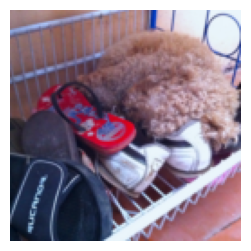

In [80]:
plt.figure(figsize=(3,3))
out=torchvision.utils.make_grid(test_image,1,normalize=True)
plt.axis(False)
plt.imshow(out.numpy().transpose((1,2,0)))
print(test_captions[0])

In [81]:
sos_token=101*torch.ones(1,1).long()
temp=0.5

In [84]:
def make_prediction(model,sos_token,eos_token,image,max_len,temp,device):
    log_tokens=[sos_token]
    model.eval()
    with torch.inference_mode():
        with torch.cuda.amp.autocast():
            image_embedding=model.encoder(image.to(device))
            for i in range(max_len):
                input_tokens=torch.cat(log_tokens,1)
                data_pred=model.decoder(input_tokens.to(device),image_embedding)
                dist=Categorical(logits=data_pred[:,-1]/temp)
                next_tokens=dist.sample().reshape(1,1)
                log_tokens.append(next_tokens.cpu())
                if next_tokens.item()==eos_token:
                    break
    return log_tokens


In [85]:
log_tokens = make_prediction(
    model=model,
    sos_token=sos_token,
    eos_token=102,
    image=test_image,
    max_len=50,
    temp=temp,
    device=device,
)

/tmp/ipykernel_1625992/2065423831.py:5: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/home/userdd42b8f1464b993aa2a3f9ad43bc/gpt-env/lib/python3.12/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


In [86]:
pred_text = torch.cat(log_tokens, 1)
print(pred_text)

decoded_text = tokenizer.decode(
    pred_text[0], skip_special_tokens=True
)  # Decode the target tokens

tensor([[  101,  1037,  4937,  2003,  3564,  2006,  1037,  6411,  2007,  1037,
         11389,  4562,  1012,   102]])


a cat is sitting on a couch with a teddy bear.


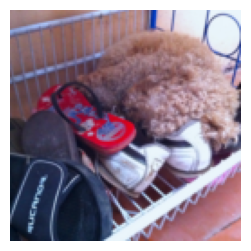

In [87]:
print(decoded_text)

plt.figure(figsize=(3, 3))
out = torchvision.utils.make_grid(test_image, 1, normalize=True)
plt.axis(False)
plt.imshow(out.numpy().transpose((1, 2, 0)))

In [88]:
def random_pred(dataloader, loader_index, model, sos_token, temp, device):
    data_iter = next(iter(dataloader))

    images, captions = data_iter

    image = images[loader_index].unsqueeze(0)
    caption = captions[loader_index]

    plt.figure(figsize=(3, 3))
    out = torchvision.utils.make_grid(image, 1, normalize=True)
    plt.axis(False)
    plt.imshow(out.numpy().transpose((1, 2, 0)))
    print(f"True: {caption}")

    log_tokens = make_prediction(
        model=model,
        sos_token=sos_token,
        eos_token=102,
        image=image,
        max_len=50,
        temp=temp,
        device=device,
    )
    pred_text = torch.cat(log_tokens, 1)
    decoded_text = tokenizer.decode(pred_text[0], skip_special_tokens=True)

    print(f"Pred: {decoded_text}")

In [1]:
%pwd

'C:\\Users\\bharg'

True: Motorcycle parked in the parking lot of asphalt.
Pred: a motorcycle is parked on the side of a street.


/tmp/ipykernel_1625992/2065423831.py:5: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


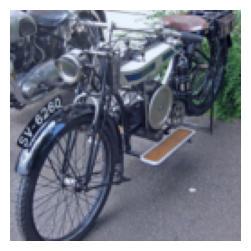

In [89]:
random_pred(
    dataloader=val_dataloader,
    loader_index=1,
    model=model,
    sos_token=sos_token,
    temp=temp,
    device=device,
)